# ML Factor Models with Purged Cross-Validation

A backtest is only as honest as the way it was validated. In financial data, shuffling rows into folds lets a model peek at information from the same month or from overlapping windows, and the result can look far better than it will ever do live. This notebook measures how big that illusion is for four model families, against purged validation and a true walk-forward test.

**What it does.** It predicts next-month returns of the 49 Fama–French industry portfolios from factor characteristics with linear, elastic-net, gradient-boosting and neural-network models.

It then shows how much the usual shuffled cross-validation **overstates** their skill compared with purged, embargoed cross-validation and a true walk-forward test.

**Data.** The Kenneth French Data Library: monthly returns of 49 value-weighted industry portfolios, the Fama–French 5 factors and momentum, 1990–2026. The VIX index (Yahoo Finance) is a market-state feature.

**Methods.** Rolling characteristics (momentum, reversal, volatility, factor betas), OLS, Elastic Net, LightGBM and an MLP.

Three validation designs are compared: shuffled K-fold, purged group K-fold with an embargo (López de Prado, 2018) and an expanding walk-forward. Skill is measured by information coefficients, out-of-sample R² and long–short portfolio Sharpe ratios.

**Key output.** The size of the leakage bias by model and metric, walk-forward performance against a plain momentum sort, and feature importance.

## 1. Why validation design matters more than the model

Financial panels break the i.i.d. assumption behind ordinary cross-validation in two ways:

1. **Common shocks within a month.** All 49 industries share the market move of that month. If shuffled K-fold puts Food in the test fold and Banks in the training fold *for the same month*, the model can learn that month's market return from the training rows. A month-level feature such as the VIX acts like a month identifier, which makes this easy.
2. **Serial overlap.** Features are built from rolling windows (12 to 36 months), so neighbouring months look alike. A test month whose neighbours are in training is not really "unseen".

**Purged group K-fold** splits by *month*, so a month is entirely in train or in test, and **embargoes** 12 months on each side of every test block, so overlapping windows cannot leak. A **walk-forward** test, which trains only on the past, is the real out-of-sample benchmark. The gap between the three is what a model validator needs to see before trusting a backtest.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import zipfile
import lightgbm as lgb
import yfinance as yf
from scipy.stats import spearmanr
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

# VIX starts in 1990; walk-forward predictions from 2000
START, WF_START = "1990-01", 2000
# months removed on each side of a purged test block
EMBARGO = 12
N_FOLDS = 5
# industries in each leg of the long–short portfolio
N_LONG = 10
SEED = 41
FRENCH = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "OLS": PALETTE[3],
    "Elastic Net": PALETTE[0],
    "LightGBM": PALETTE[2],
    "MLP": PALETTE[1],
}
CV_COLORS = {
    "shuffled K-fold": STATUS["red"],
    "purged + embargo": STATUS["amber"],
    "walk-forward": PALETTE[0],
}

## 3. Data: Kenneth French Data Library and the VIX

In [3]:
def read_french(fname, section_start=None):
    """
    Download a French zip and parse the first monthly table (YYYYMM rows) into
    a DataFrame in decimals.
    """
    for attempt in range(3):
        try:
            raw = requests.get(
                FRENCH + fname, headers=BROWSER_HEADERS, timeout=60
            ).content
            break
        except requests.RequestException:
            time.sleep(3)
    z = zipfile.ZipFile(io.BytesIO(raw))
    lines = z.read(z.namelist()[0]).decode("latin1").splitlines()
    start = next(
        i
        for i, l in enumerate(lines)
        if (section_start is None and re.match(r"^\s*,", l))
        or (section_start and section_start in l)
    )
    if section_start:
        start += 1
    header = [c.strip() for c in lines[start].split(",")]
    rows = []
    for l in lines[start + 1 :]:
        parts = [p.strip() for p in l.split(",")]
        if not re.match(r"^\d{6}$", parts[0]):
            break
        rows.append(parts)
    df = (
        pd.DataFrame(rows, columns=["date"] + header[1:])
        .set_index("date")
        .astype(float)
    )
    df.index = pd.to_datetime(df.index, format="%Y%m") + pd.offsets.MonthEnd(0)
    return df.replace([-99.99, -999], np.nan) / 100


def fetch_french():
    ind = read_french(
        "49_Industry_Portfolios_CSV.zip",
        "Average Value Weighted Returns -- Monthly",
    )
    ff5 = read_french("F-F_Research_Data_5_Factors_2x3_CSV.zip")
    mom = read_french("F-F_Momentum_Factor_CSV.zip")
    out = ind.join(ff5, how="left").join(mom, how="left")
    return out.reset_index()


def fetch_vix():
    v = yf.download(
        "^VIX", start="1990-01-01", auto_adjust=True, progress=False
    )["Close"]
    v = v.iloc[:, 0] if isinstance(v, pd.DataFrame) else v
    v.index = pd.to_datetime(v.index).tz_localize(None)
    return (
        v.resample("ME")
        .last()
        .rename("VIX")
        .to_frame()
        .reset_index(names="date")
    )


french = cached(
    "french_industries_factors", fetch_french, max_age_hours=24 * 7
).set_index("date")
vix = cached("yahoo_vix_monthly", fetch_vix, max_age_hours=24 * 7).set_index(
    "date"
)["VIX"]
FACTORS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
mom_col = [c for c in french.columns if c.lower().startswith("mom")][0]
INDUSTRIES = [c for c in french.columns if c not in FACTORS + ["RF", mom_col]]
data = french.loc[START:].dropna(subset=FACTORS)
excess = data[INDUSTRIES].sub(data["RF"], axis=0)
print(
    f"{len(INDUSTRIES)} industries · {data.index.min():%Y-%m} →"
    f" {data.index.max():%Y-%m} ({len(data)} months) · VIX months"
    f" {vix.notna().sum()}"
)

49 industries · 1990-01 → 2026-08 (440 months) · VIX months 442


## 4. Characteristics

At each month-end $t$, for each industry, using only data up to $t$:

- **r1:** last month's return (short-term reversal);
- **mom 12-1:** cumulative return from $t-11$ to $t-1$ (momentum, skipping the last month);
- **rev 36-13:** long-term reversal;
- **vol 12:** volatility of monthly returns over 12 months;
- **β market, β SMB, β HML, β RMW, β CMA, β UMD:** rolling 36-month factor loadings, plus idiosyncratic volatility;
- **market state** (the same for all industries in a month): VIX level and its 1-month change, and the market's 12-month return.

Industry characteristics are converted to **cross-sectional ranks** in $[-0.5, 0.5]$ each month, the standard way to make them comparable over time. The target is the **next month's excess return**.

In [4]:
R = data[INDUSTRIES]
F = data[FACTORS + [mom_col]]
feat = {}
feat["r1"] = R
feat["mom 12-1"] = (1 + R).rolling(11).apply(np.prod, raw=True).shift(1) - 1
feat["rev 36-13"] = (1 + R).rolling(24).apply(np.prod, raw=True).shift(12) - 1
feat["vol 12"] = R.rolling(12).std()
betas = {
    f: pd.DataFrame(index=R.index, columns=INDUSTRIES, dtype=float)
    for f in FACTORS + [mom_col]
}
ivol = pd.DataFrame(index=R.index, columns=INDUSTRIES, dtype=float)
Xf = np.column_stack([np.ones(len(F)), F.values])
for i in range(36, len(R) + 1):
    Xw = Xf[i - 36 : i]
    Yw = excess.values[i - 36 : i]
    ok = ~np.isnan(Yw).any(axis=0)
    B = np.linalg.lstsq(Xw, np.nan_to_num(Yw), rcond=None)[0]
    res = np.nan_to_num(Yw) - Xw @ B
    for k, f in enumerate(FACTORS + [mom_col]):
        betas[f].iloc[i - 1] = np.where(ok, B[k + 1], np.nan)
    ivol.iloc[i - 1] = np.where(ok, res.std(axis=0), np.nan)
for f in FACTORS + [mom_col]:
    feat[f"β {f}"] = betas[f]
feat["idio vol"] = ivol

rows = []
for name, df in feat.items():
    ranked = df.rank(axis=1, pct=True) - 0.5
    rows.append(ranked.stack().rename(name))
panel = pd.concat(rows, axis=1)
panel.index.names = ["date", "industry"]
mkt_state = pd.DataFrame({
    "VIX": vix.reindex(R.index) / 100,
    "ΔVIX": vix.reindex(R.index).diff() / 100,
    "market 12m": (1 + data["Mkt-RF"] + data["RF"]).rolling(12).apply(
        np.prod, raw=True
    ) - 1,
})
panel = panel.join(mkt_state, on="date")
panel["target"] = excess.shift(-1).stack().reindex(panel.index)
panel = panel.dropna()
FEATURES = [c for c in panel.columns if c != "target"]
months = panel.index.get_level_values("date")
print(
    f"Panel: {len(panel):,} industry-months · {months.nunique()} months ·"
    f" {len(FEATURES)} features"
)
# Ranked features all share the same uniform distribution, so a describe()
# table says nothing.
# Instead show each feature's univariate predictive power: the mean monthly
# rank IC with next-month returns.
uni = {
    f: panel.groupby(level="date").apply(
        lambda g: g[f].corr(g["target"], method="spearman")
    )
    for f in FEATURES[:11]
}
uni = pd.DataFrame({
    "mean IC": {f: v.mean() for f, v in uni.items()},
    "IC t-stat": {
        f: v.mean() / v.std() * np.sqrt(v.notna().sum())
        for f, v in uni.items()
    },
})
uni.round(3).sort_values("mean IC", ascending=False)

Panel: 19,796 industry-months · 404 months · 14 features


,mean IC,IC t-stat
mom 12-1,0.04,2.86
β HML,0.02,1.61
β RMW,0.01,1.18
r1,0.01,0.84
β SMB,0.01,0.71
β Mom,0.01,0.45
vol 12,0.01,0.38
β Mkt-RF,0.00,0.26
rev 36-13,0.00,0.22
idio vol,-0.01,-0.71


## 5. Models and the three validation schemes

| Model | Settings |
|---|---|
| OLS | all features, no regularisation |
| Elastic Net | penalty chosen by internal 5-fold CV, 50/50 L1/L2 |
| LightGBM | 300 trees, 15 leaves, learning rate 0.03, row and column subsampling |
| MLP | 2 hidden layers (32, 16), L2 penalty, early stopping |

Metrics on held-out predictions:

- **OOS R²** against a zero forecast (no in-sample mean): $1-\sum(y-\hat y)^2/\sum y^2$.
- **IC:** the mean monthly Spearman correlation between predictions and realised returns across industries.
- **Long–short Sharpe:** buy the 10 industries with the highest predicted return and sell the 10 lowest, equally weighted, rebalanced monthly.

In [5]:
def make_models():
    return {
        "OLS": LinearRegression(),
        "Elastic Net": ElasticNetCV(
            l1_ratio=0.5, cv=5, alphas=30, random_state=SEED, max_iter=5_000
        ),
        "LightGBM": lgb.LGBMRegressor(
            n_estimators=300,
            num_leaves=15,
            learning_rate=0.03,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            min_child_samples=50,
            random_state=SEED,
            verbose=-1,
        ),
        "MLP": MLPRegressor(
            hidden_layer_sizes=(32, 16),
            alpha=1e-3,
            early_stopping=True,
            max_iter=300,
            random_state=SEED,
        ),
    }


X_all, y_all = panel[FEATURES].to_numpy(), panel["target"].to_numpy()
month_codes = pd.factorize(months)[0]
uniq = np.unique(month_codes)


def evaluate(pred, idx):
    df = pd.DataFrame({"m": month_codes[idx], "y": y_all[idx], "p": pred})
    r2 = 1 - np.sum((df["y"] - df["p"]) ** 2) / np.sum(df["y"] ** 2)
    # A fully shrunk Elastic Net can predict the same value for every industry
    # in a month; the rank correlation is undefined there, so those months are
    # skipped rather than warned about.
    ic = (
        df.groupby("m")
        .apply(
            lambda g: (
                spearmanr(g["p"], g["y"])[0]
                if g["p"].nunique() > 1
                else np.nan
            )
        )
        .mean()
    )
    ls = df.groupby("m").apply(
        lambda g: g.nlargest(N_LONG, "p")["y"].mean()
        - g.nsmallest(N_LONG, "p")["y"].mean()
    )
    return {
        "OOS R² %": r2 * 100,
        "IC": ic,
        "long-short Sharpe": ls.mean() / ls.std() * np.sqrt(12),
    }


def cv_scores(splitter):
    out = {m: np.full(len(y_all), np.nan) for m in make_models()}
    for tr, te in splitter:
        for name, model in make_models().items():
            model.fit(X_all[tr], y_all[tr])
            out[name][te] = model.predict(X_all[te])
    return out


# (a) shuffled K-fold over rows: the textbook default
shuffled = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(X_all))
# (b) purged group K-fold by contiguous month blocks, with an embargo of
# EMBARGO months on each side
blocks = np.array_split(uniq, N_FOLDS)
purged = []
for b in blocks:
    lo, hi = b.min() - EMBARGO, b.max() + EMBARGO
    te = np.isin(month_codes, b)
    tr = (month_codes < lo) | (month_codes > hi)
    purged.append((np.flatnonzero(tr), np.flatnonzero(te)))
t0 = time.perf_counter()
pred_shuf, pred_purg = cv_scores(shuffled), cv_scores(purged)
print(
    "Cross-validation (2 schemes × 5 folds × 4 models) in"
    f" {time.perf_counter() - t0:.0f}s"
)

Cross-validation (2 schemes × 5 folds × 4 models) in 17s


### Walk-forward: train on the past only

Each January from 2000, every model is refitted on all months up to the previous November (one month of gap, so the last training target is fully known), then predicts the 12 months of the year. This is the only one of the three schemes a real investor could have run.

In [6]:
years = months.year
pred_wf = {m: np.full(len(y_all), np.nan) for m in make_models()}
t0 = time.perf_counter()
for yr in range(WF_START, years.max() + 1):
    te = np.flatnonzero(years == yr)
    cutoff = pd.Timestamp(f"{yr - 1}-11-30")
    tr = np.flatnonzero(months <= cutoff)
    if len(te) == 0:
        continue
    for name, model in make_models().items():
        model.fit(X_all[tr], y_all[tr])
        pred_wf[name][te] = model.predict(X_all[te])
print(
    "Walk-forward"
    f" {WF_START}–{years.max()} ({years.max() - WF_START + 1} refits × 4"
    f" models) in {time.perf_counter() - t0:.0f}s"
)

wf_idx = np.flatnonzero(years >= WF_START)
rows = []
for scheme, preds in [
    ("shuffled K-fold", pred_shuf),
    ("purged + embargo", pred_purg),
    ("walk-forward", pred_wf),
]:
    idx = wf_idx if scheme == "walk-forward" else np.arange(len(y_all))
    for name in MODEL_COLORS:
        rows.append({
            "scheme": scheme,
            "model": name,
            **evaluate(preds[name][idx], idx),
        })
# Benchmark: a plain momentum sort, no model at all
mom_idx = FEATURES.index("mom 12-1")
rows.append({
    "scheme": "walk-forward",
    "model": "Momentum sort (no model)",
    # a ranking, not a return forecast
    **{**evaluate(X_all[wf_idx, mom_idx], wf_idx), "OOS R² %": np.nan},
})
scores = pd.DataFrame(rows).set_index(["scheme", "model"])
scores.round(3)

Walk-forward 2000–2026 (27 refits × 4 models) in 54s


OOS R² %    IC  long-short Sharpe
scheme           model                                                      
shuffled K-fold  OLS                           2.02  0.04               0.49
                 Elastic Net                   1.39  0.03               0.38
                 LightGBM                     33.89 -0.00              -0.01
                 MLP                           1.94  0.02               0.47
purged + embargo OLS                           0.51  0.01               0.12
                 Elastic Net                   0.96  0.02               0.07
                 LightGBM                    -10.55 -0.01              -0.01
                 MLP                          -1.45  0.01               0.21
walk-forward     OLS                          -0.41  0.01               0.12
                 Elastic Net                   0.17  0.01              -0.04
                 LightGBM                     -9.11  0.02               0.49
                 MLP                          -0.31  0.02               0.40
                 Momentum sort (no model)       NaN  0.03               0.20

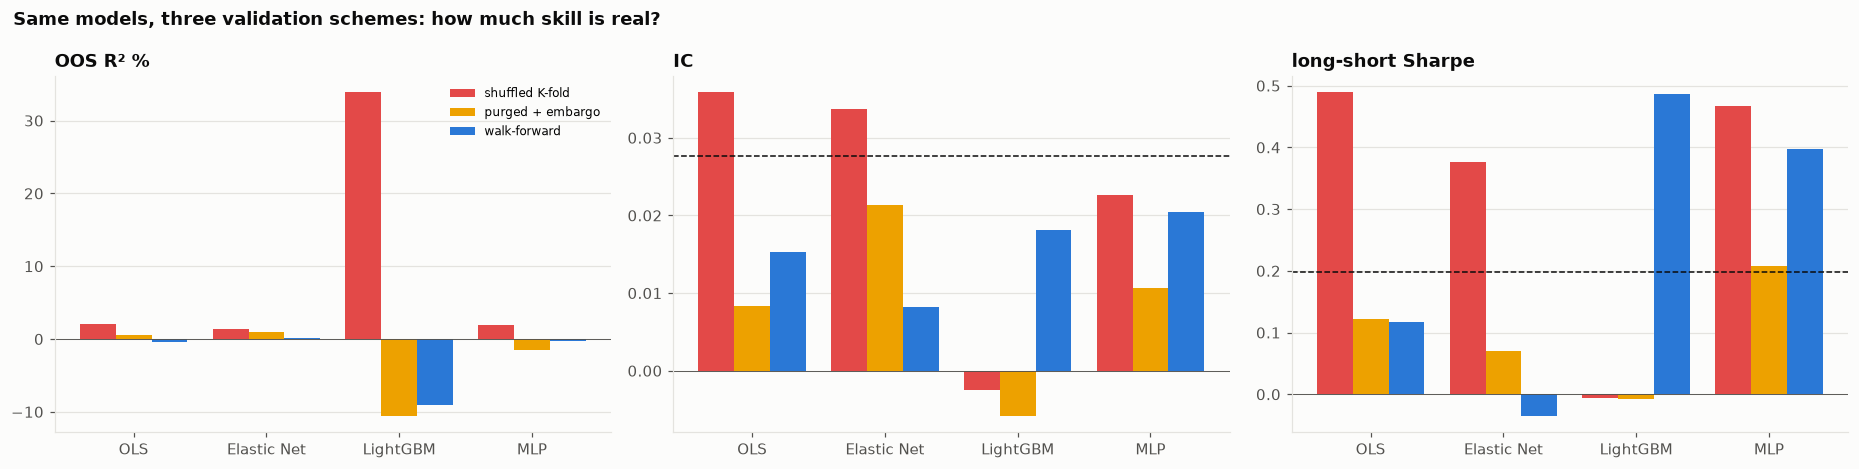

In [7]:
# --- Chart 1: the leakage gap
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for ax, metric in zip(axes, ["OOS R² %", "IC", "long-short Sharpe"]):
    xp = np.arange(len(MODEL_COLORS))
    for k, (scheme, color) in enumerate(CV_COLORS.items()):
        vals = [scores.loc[(scheme, m), metric] for m in MODEL_COLORS]
        ax.bar(xp + (k - 1) * 0.27, vals, 0.27, color=color, label=scheme)
    if metric != "OOS R² %":
        ax.axhline(
            scores.loc[("walk-forward", "Momentum sort (no model)"), metric],
            color=INK,
            ls="--",
            lw=1,
            label="momentum sort (walk-forward)",
        )
    ax.axhline(0, color=INK_2, lw=0.6)
    ax.set_xticks(xp, list(MODEL_COLORS))
    ax.set_title(metric)
    ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8)
fig.suptitle(
    "Same models, three validation schemes: how much skill is real?",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
save_fig(fig, "01_leakage_gap")
plt.show()

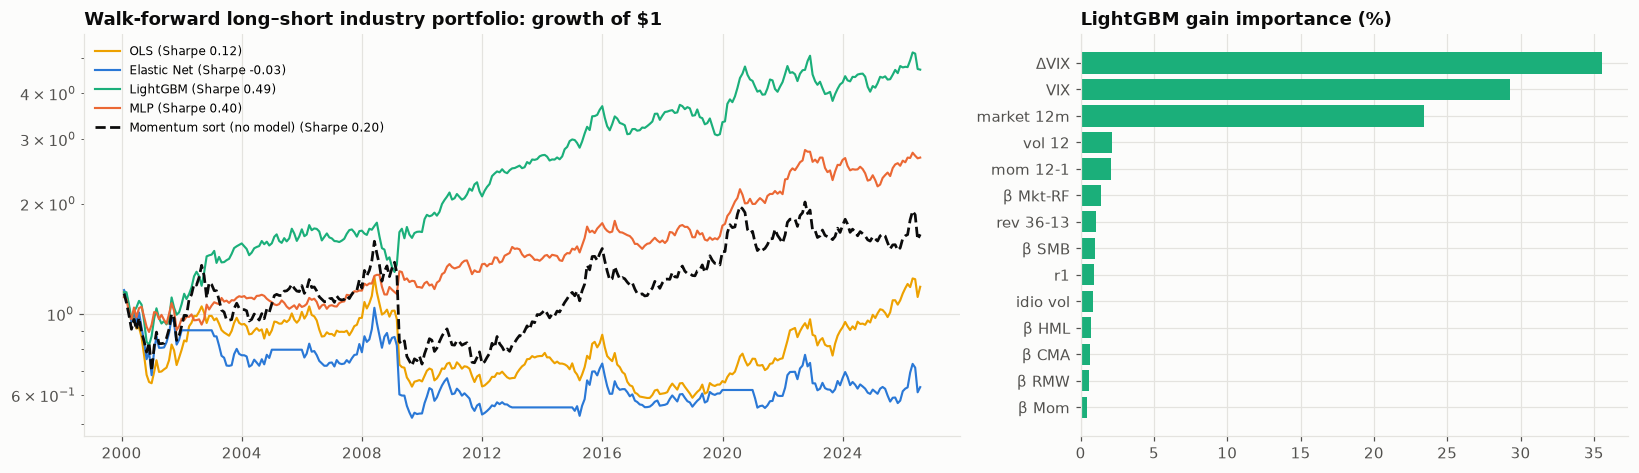

In [8]:
# --- Chart 2: walk-forward long–short wealth and LightGBM feature importance
fig, axes = plt.subplots(
    1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.6, 1]}
)
ax = axes[0]
dates_wf = months[wf_idx]
for name, color in list(MODEL_COLORS.items()) + [
    ("Momentum sort (no model)", INK)
]:
    p = pred_wf[name][wf_idx] if name in pred_wf else X_all[wf_idx, mom_idx]
    df = pd.DataFrame({"d": dates_wf, "y": y_all[wf_idx], "p": p})
    ls = df.groupby("d").apply(
        lambda g: g.nlargest(N_LONG, "p")["y"].mean()
        - g.nsmallest(N_LONG, "p")["y"].mean()
    )
    ax.plot(
        ls.index,
        (1 + ls).cumprod(),
        color=color,
        lw=1.4 if name in MODEL_COLORS else 1.8,
        ls="-" if name in MODEL_COLORS else "--",
        label=f"{name} (Sharpe {ls.mean() / ls.std() * np.sqrt(12):.2f})",
    )
ax.set_yscale("log")
ax.set_title("Walk-forward long–short industry portfolio: growth of $1")
ax.legend(fontsize=8)
ax = axes[1]
gbm = make_models()["LightGBM"].fit(X_all, y_all)
imp = pd.Series(
    gbm.booster_.feature_importance("gain"), index=FEATURES
).sort_values()
ax.barh(imp.index, imp.values / imp.sum() * 100, color=PALETTE[2])
ax.set_title("LightGBM gain importance (%)")
plt.tight_layout()
save_fig(fig, "02_walk_forward_and_importance")
plt.show()
scores.to_csv(OUT_DIR / "validation_scores.csv")
pd.DataFrame({
    "date": months[wf_idx],
    "industry": panel.index.get_level_values("industry")[wf_idx],
    "target": y_all[wf_idx],
    **{f"pred {m}": pred_wf[m][wf_idx] for m in MODEL_COLORS},
}).to_csv(OUT_DIR / "walk_forward_predictions.csv", index=False)

## 6. Reading the results and limitations

Results for 49 industries, 1993–2026 (walk-forward from 2000):

**Shuffled K-fold manufactures skill.** LightGBM scores an out-of-sample R² of **34%** under shuffled K-fold, an impossible number for monthly returns. Under purged K-fold it falls to −11%, and in the walk-forward test to −9%. The mechanism is visible in the importance chart: 88% of LightGBM's gain comes from the three **market-state** features (ΔVIX, VIX, trailing market return).

These features are identical for all 49 industries in a month, so they act as a month identifier. With shuffled folds, other industries from the same month sit in the training set, and the trees simply memorise that month's market return. Its IC under shuffled CV is zero: the "skill" is all about time, not about ranking industries.

- **Linear models leak less but still flatter themselves.** OLS goes from R² 2.0% and a long–short Sharpe of 0.49 (shuffled) to 0.5% and 0.12 (purged), and to −0.4% and 0.12 walk-forward. Most of the apparent edge disappears once the overlap in time is removed.
- **Honest R² is about zero for every model.** None of the four models forecasts the *level* of next month's industry returns better than zero. The Elastic Net often shrinks all coefficients to zero (the flat stretches of its wealth line are months in which it predicts the same return for every industry, so it holds no real position).

**Ranking is a different question from forecasting.** Walk-forward, LightGBM and the MLP still rank industries usefully: long–short Sharpe ratios of **0.49** and **0.40**, against **0.20** for a plain 12-1 momentum sort. LightGBM does this with a negative R², because it uses the VIX features to decide *which* characteristics matter in which regime rather than to forecast the level.

With a 27-year sample, a Sharpe of 0.49 has a t-statistic of about 2.5, before costs and before any allowance for having tried four models.

- **Univariate evidence is thin.** Only 12-1 momentum (IC 0.04, t = 2.9) and, negatively, the CMA beta (t = −2.1) have a monthly rank IC that is clearly different from zero. Most characteristics carry almost no signal at industry level.
- **For model validation,** the practical rule is to use purged and embargoed folds, or walk-forward, for any panel with common time effects, and to report the gap against shuffled CV as a leakage diagnostic. A model whose shuffled and purged scores diverge as much as LightGBM's here should not pass validation on the shuffled numbers.

**Limitations**

- Industry portfolios are diversified, so return predictability is far weaker than in single stocks, which is where ML factor models report their largest gains (Gu, Kelly & Xiu, 2020).
- Hyper-parameters are fixed and not tuned inside each fold. Tuning by shuffled CV would add a second layer of the same leakage.
- Long–short returns are gross of costs; industry portfolios turn over slowly, but a 10-vs-10 sort still trades every month.

## References

### Finance and regulation

- Fama, E. F., & French, K. R. (2015). A five-factor asset pricing model. *Journal of Financial Economics, 116*(1), 1–22. https://doi.org/10.1016/j.jfineco.2014.10.010
- Moskowitz, T. J., & Grinblatt, M. (1999). Do industries explain momentum? *The Journal of Finance, 54*(4), 1249–1290. https://doi.org/10.1111/0022-1082.00146
- Harvey, C. R., Liu, Y., & Zhu, H. (2016). … and the cross-section of expected returns. *The Review of Financial Studies, 29*(1), 5–68. https://doi.org/10.1093/rfs/hhv059
- Campbell, J. Y., & Thompson, S. B. (2008). Predicting excess stock returns out of sample: Can anything beat the historical average? *The Review of Financial Studies, 21*(4), 1509–1531. https://doi.org/10.1093/rfs/hhm055
- Gu, S., Kelly, B., & Xiu, D. (2020). Empirical asset pricing via machine learning. *The Review of Financial Studies, 33*(5), 2223–2273. https://doi.org/10.1093/rfs/hhaa009

### Machine learning and deep learning

- Arlot, S., & Celisse, A. (2010). A survey of cross-validation procedures for model selection. *Statistics Surveys, 4*, 40–79. https://doi.org/10.1214/09-SS054
- Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences, 191*, 192–213. https://doi.org/10.1016/j.ins.2011.12.028
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html